In [214]:
import torch
import torch.nn.functional as F

words = open("names.txt", "r").read().splitlines()

alphabet = sorted(list(set("".join(words))))
stoi = {alphabet[i] : i + 1 for i in range(26)}
stoi["."] = 0
itos = {i : letter for letter, i in stoi.items()}
vocab_size = len(alphabet) + 1

print(f"Num training examples: {len(words)}")

Num training examples: 32033


In [222]:
class Linear:
    def __init__(self, fan_in, fan_out, bias=True):
        self.fan_in = fan_in
        self.fan_out = fan_out
        self.bias = bias

        self.weights = torch.randn(fan_in, fan_out)/fan_in**0.5  # kaiming
        self.biases = torch.zeros(fan_out) if bias else None

    def __call__(self, inp):
        prod = inp@self.weights
        if self.biases is not None:
            prod += self.biases
        self.out = prod
        return self.out

    def parameters(self):
        biases = [self.biases] if self.biases is not None else []
        return [self.weights] + biases

    def reset_params(self):
        self.weights = torch.randn(self.fan_in, self.fan_out)/self.fan_in**0.5
        self.biases = torch.zeros(self.fan_out) if self.bias else None

class BatchNorm1d:
    def __init__(self, dim, eps=1e-05, momentum=0.1, training = True):
        self.eps = eps
        self.momentum = momentum
        self.dim = dim

        self.training = training

        self.gamma = torch.ones(1, dim)
        self.beta = torch.zeros(1, dim)

        self.running_mean = torch.zeros(1, dim)
        self.running_var = torch.ones(1, dim)

    def __call__(self, inp):
        if self.training:
            bn_mean = inp.mean(dim=0, keepdim=True)
            bn_var = inp.var(dim=0, keepdim=True, unbiased=False)
        else:
            bn_mean = self.running_mean
            bn_var = self.running_var

        inp_norm = (inp - bn_mean) / torch.sqrt(bn_var+self.eps)
        inp_bn = self.gamma * inp_norm + self.beta

        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * bn_mean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * bn_var

        self.out = inp_bn
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]

    def reset_params(self):
        self.gamma = torch.ones(1, self.dim)
        self.beta = torch.zeros(1, self.dim)

        self.running_mean = torch.zeros(1, self.dim)
        self.running_var = torch.ones(1, self.dim)

class Dropout:
    def __init__(self, p = 0.5):
        self.distr = torch.tensor([1 - p, p])
        self.p = p

    def __call__(self, inp):
        num_elements = inp.view(-1).shape[0]
        mask = torch.multinomial(self.distr, num_elements, replacement=True).view(inp.shape)
        self.out = mask*inp
        return self.out

    def parameters(self):
        return []

class Tanh:
    def __call__(self, inp):
        self.out = torch.tanh(inp)
        return self.out

    def parameters(self):
        return []

class ReLU:
    def __call__(self, inp):
        self.out = torch.relu_(inp)
        return self.out

    def parameters(self):
        return []

class PReLU:
    def __init__(self):
        self.weight = torch.randn(1)
    def __call__(self, inp):
        self.out = torch.prelu(inp, self.weight)
        return self.out

    def parameters(self):
        return [self.weight]

    def reset_params(self):
        self.weight = torch.randn(1)

class SoftMax:
    def __call__(self, arr):
        logits = torch.exp(arr)
        self.out = logits/logits.sum(dim = 1)
        return self.out

    def parameters(self):
        return []

class Embedding:
    def __init__(self, vocab_size, emb_size):
        self.vocab_size = vocab_size
        self.emb_size = emb_size

        self.weight = torch.randn((vocab_size, emb_size))

    def __call__(self, inp):
        self.out = self.weight[inp]
        return self.out

    def parameters(self):
        return [self.weight]

    def reset_params(self):
        self.weight = torch.randn((self.vocab_size, self.emb_size))

class Flatten:
    def __call__(self, arr):
        shape = 1 if len(arr.shape) == 2 else arr.shape[0]
        self.out = arr.view(shape, -1)
        return self.out

    def parameters(self):
        return []

class Sequential:
    def __init__(self, layers):
        self.layers = layers
        self.params = [p for layer in self.layers for p in layer.parameters()]

    def __call__(self, inp):
        self.out = inp
        for layer in self.layers:
            self.out = layer(self.out)
        return self.out

    def n_parameters(self):
        return sum(p.nelement() for p in self.params)

    def reset_params(self, seed=None):
        if seed is not None:
            torch.manual_seed(seed)
        for layer in self.layers:
            if hasattr(layer, 'reset_params'):
                layer.reset_params()
        self.params = [p for layer in self.layers for p in layer.parameters()]

In [216]:
n_embd = 2
n_hidden = 300
context_size = 10

X = []
Y = []

for word in words:
    word_context = [0] * context_size
    for ch in word + ".":
        X.append(word_context.copy())
        Y.append(torch.tensor(stoi[ch]))
        word_context = word_context[1:] + [stoi[ch]]

X_train = torch.tensor(X[:159702])
Y_train = torch.tensor(Y[:159702])
X_val = torch.tensor(X[159702:205331])
Y_val = torch.tensor(Y[159702:205331])
X_test = torch.tensor(X[205331:])
Y_test = torch.tensor(Y[205331:])

In [221]:
seed = 232325325  # can be changed while experimenting
gain = {"Tanh" : (5/3)**0.5, "ReLU" : 2**0.5}

# Model structure define

model = Sequential([
    Embedding(vocab_size, n_embd),
    Flatten(),
    Linear(context_size*n_embd, n_hidden), ReLU(),
    Linear(n_hidden, n_hidden), Tanh(),
    Linear(n_hidden, n_hidden), Tanh(),
    Linear(n_hidden, n_hidden), Tanh(),
    Linear(n_hidden, n_hidden), Tanh(),
    Linear(n_hidden, vocab_size)])

# Initializing weightss

n = len(model.layers)

with torch.no_grad():
    if isinstance(model.layers[-1], Linear):
        model.layers[-1].weights *= 0.01
    elif isinstance(model.layers[-1], BatchNorm1d):
        model.layers[-1].gamma *= 0.01

    for i in range(n - 1):
        layer = model.layers[i]
        if isinstance(layer, Linear):
            if i < n - 1 and model.layers[i+1].__class__.__name__ in gain:
                layer.weights *= gain[model.layers[i+1].__class__.__name__]
        if isinstance(layer, BatchNorm1d):
            layer.training = True

        model.layers[i] = layer

print("Number of parameters: ", model.n_parameters())

for p in model.params:
    p.requires_grad = True

Number of parameters:  375681


In [207]:
def print_description(iterations, batch_size, learn ,lr_arch, momentum, beta1, beta2, gamma, eps, alpha, beta, L1_regularization, L2_regularization, corpus):
    print(f"iterations: {iterations}, batch_size: {batch_size}, alpha: {alpha}, beta: {beta}, corpus size: {corpus}")
    st = ""
    if L1_regularization:
        st += " L1 Regularization valid"
    if L2_regularization:
        st += " L2 Regularization valid"
    lr_arch_dict = {
        "momentum based" : f" Momentum based , momentum = {momentum} ",
        "adagrad"        : f" AdaGrad , eps = {eps} ",
        "rmsprop"        : f" RMSprop , gamma = {gamma}, eps = {eps} ",
        "adam"           : f" Adam , Beta1 = {beta1} , beta2 = {beta2} ",
        None             : f" Batch GD , learning rate = {learn} "
    }
    st += lr_arch_dict[lr_arch]
    st += f", learn rate = {learn}"
    print(st)

In [208]:
def train_model(iterations, batch_size, model, train_keys, train_values, learn = 0.1, lr_arch = None, momentum = 0.1, beta1 = 0.9, beta2 = 0.9, t = 2 ,gamma = 0.9, eps = 1e-5, alpha = 0.01, beta = 0.01, L1_regularization = False, L2_regularization = False, seed=None):
    # ------------------------------   INIIALIZATION AND PRINTING STUFF   -----------------------------------------
    model.reset_params(seed)
    corpus = train_values.shape[0]
    print_description(iterations, batch_size, lr_arch = lr_arch,\
                      momentum = momentum, beta1 = beta1, beta2 = beta2, gamma = gamma,\
                      eps = eps, alpha = alpha, beta = beta, learn = learn, \
                      L1_regularization=L1_regularization , L2_regularization=L2_regularization, corpus = corpus)

    train_loss = []
    val_loss = []

    for p in model.params:
        p.requires_grad = True

    if lr_arch == "momentum based":
        velocities = [torch.zeros_like(p) for p in model.params]
    if lr_arch == "adagrad":
        accum_grad = [torch.zeros_like(p) for p in model.params]
    if lr_arch == "rmsprop":
        accum_grad_exp = [torch.zeros_like(p) for p in model.params]
    if lr_arch ==  "adam":
        accum_mt = [torch.zeros_like(p) for p in model.params]
        accum_vt = [torch.zeros_like(p) for p in model.params]

    # -------------------------------------training and backprop--------------------------------------------------------------

    for _ in range(iterations):
        # Forward Pass
        ix = torch.randint(0, train_keys.shape[0], (batch_size,))
        Xb, Yb = train_keys[ix], train_values[ix]

        x = model(Xb)

        ridge = 0
        lasso = 0
        if L2_regularization:
            for l in model.layers:
                if isinstance(l, Linear):
                    ridge = ridge + (l.weights**2).mean()

        if L1_regularization:
            for l in model.layers:
                if isinstance(l, Linear):
                    lasso = lasso + (abs(l.weights)).mean()

        loss = F.cross_entropy(x, Yb) + alpha*ridge + beta*lasso

        # Backward pass
        for p in model.params:
            p.grad = None

        loss.backward()

        # update steps
        lr = learn
        for i in range(len(model.params)):
            if lr_arch == "adam":
                accum_mt[i] = beta1*accum_mt[i] + (1-beta1)*model.params[i].grad
                accum_vt[i] = beta2*accum_vt[i] + (1-beta2)*model.params[i].grad**2

                t = _ + 1

                mt_hat = accum_mt[i]/(1-beta1**t)
                vt_hat = accum_vt[i]/(1-beta2**t)

                update = (mt_hat/(vt_hat**0.5 + eps)) * lr

            elif lr_arch == "rmsprop":
                accum_grad_exp[i] = gamma*accum_grad_exp[i] + (1-gamma)*model.params[i].grad**2
                update = (model.params[i].grad/(accum_grad_exp[i] + eps)**0.5) * lr

            elif lr_arch == "momentum based":
                velocities[i] = lr*model.params[i].grad + momentum*velocities[i]
                update = velocities[i]

            elif lr_arch == "adagrad":
                accum_grad[i] = accum_grad[i] + model.params[i].grad**2
                update = (model.params[i].grad/(accum_grad[i] + eps)**0.5) * lr

            else:
                update = lr*model.params[i].grad

            model.params[i].data += -update

        if _ % 1000 == 0:
            with torch.no_grad():
                outv = model(X_val)
                lossv = F.cross_entropy(outv, Y_val)
                # print(f"{_}/{epochs} : {loss.item()}")
                # print(f"Valdation loss: {lossv}")

            train_loss.append(loss.log10().item())
            val_loss.append(lossv.log10().item())

    return model, train_loss, val_loss

In [209]:
iterations = 100000
batch_size = 64

In [217]:
model_, train_loss, val_loss = train_model(iterations, batch_size, model, X_train, Y_train, learn = 0.01, lr_arch = "adagrad")

iterations: 100000, batch_size: 64, alpha: 0.01, beta: 0.01, corpus size: 159702
 AdaGrad , eps = 1e-05 , learn rate = 0.01


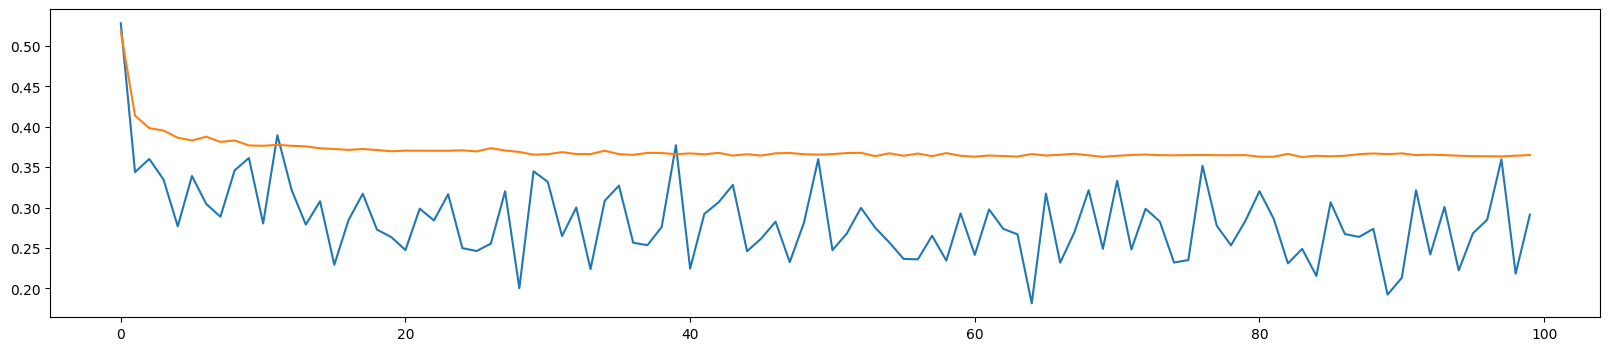

In [218]:
import matplotlib.pyplot as plt

# Plotting both validation and training loss

plt.figure(figsize=(20, 4))
train_loss_ = torch.tensor(train_loss)
val_loss_ = torch.tensor(val_loss)
plt.plot(train_loss_)
plt.plot(val_loss_)
plt.show()

In [ ]:
# Scatter plot meaningful only for 2D embedding size

import matplotlib.pyplot as plt
%matplotlib inline
C = model_.layers[0].weight
plt.scatter(C[:, 0].tolist(), C[:, 1].tolist())
for i in range(vocab_size):
    plt.text(C[:, 0].tolist()[i], C[:, 1].tolist()[i], itos[i])

In [219]:
generated_words = []
in_ = 0
for layer in model_.layers[:-1]:
    if isinstance(layer, BatchNorm1d):
        layer.training = False

num = 1000
for _ in range(num):
    word = "."*context_size
    while True:
        X_test = [stoi[word[i]] for i in range(-context_size, 0)]
        x = model_(X_test)
        Z2 = F.softmax(x)
        ch = itos[torch.multinomial(Z2, num_samples = 1).item()]

        word += ch
        if ch == ".":
            if word[context_size:-1] in words:
                in_ += 1
            else:
                generated_words.append(word[context_size:-1])
            break

print(f"Percentage new words produced out of num words: {(1 - in_/num)*100}%")

/tmp/ipykernel_797/3624157007.py:13: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  Z2 = F.softmax(x)


Percentage new words produced out of num words: 73.3%


In [220]:
print(generated_words)

['zanasia', 'katena', 'eyrika', 'aroul', 'aaruhna', 'genes', 'soliaq', 'alissandro', 'vionah', 'aydira', 'faros', 'laylie', 'matteb', 'esrenie', 'sumy', 'jieny', 'lamaa', 'edeb', 'fayegia', 'evacy', 'jameen', 'keylington', 'marysar', 'roshley', 'olamirochosu', 'droshan', 'eirel', 'danyon', 'aislie', 'thianah', 'varymarii', 'marcedene', 'evarer', 'betly', 'mirael', 'karby', 'anastahna', 'otielene', 'yarke', 'rayvia', 'elunah', 'hahlin', 'aydura', 'jameyo', 'jakires', 'marmi', 'arwikton', 'ansla', 'shamyn', 'jacynn', 'olysson', 'dresley', 'keaji', 'zentri', 'brindshi', 'joci', 'rhila', 'katikah', 'atzaa', 'regdalyn', 'levansh', 'yeslalia', 'itethi', 'chaleash', 'beyle', 'ozairia', 'learo', 'myerton', 'eyra', 'paryn', 'khncy', 'sopaiha', 'malaynah', 'cariela', 'jinia', 'linacia', 'navae', 'harianne', 'genis', 'aubryso', 'katelea', 'atlen', 'yayyde', 'dikeya', 'carolael', 'dalcylyn', 'kashtley', 'miliamae', 'lennesy', 'milpha', 'savin', 'clarise', 'harrav', 'yahlis', 'madyjin', 'sumy', 'ad